In [1]:
from datascience import *
import numpy as np
import statistics as stats
import scipy.stats as sci 
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plots
import math
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

# Week 6 - Notebook 1: 5.1

## 5.1 The Standard Normal Distribution

We want to characterize an experiment as a whole. Since the values are continuous and the data is normally distributed, we will create a symmetric curve that represents all possible outcomes. The  probabilities are represented by the area under the curve between the curve and the axis. 

These distributions use the same vocabulary as the Discrete Probability distribution. The only difference is the values are continuous and not discrete, meaning they can by any real number: decimals, fractions, or whole numbers. 

### Requirements
Same as Discrete Probabilities: 
 * Each individual probability must be between 0 and 1. $0 \leq P(x) \leq 1$ 
 * Sum of all probabilities in the table must add to 1. $\Sigma P(x) = 1$

### Normal Curve
Under a normal curve
 * the mean is in the center of the curve ($\mu, \bar{x}$)
 * the standard deviation helps define the width of the curve ($\sigma, s$)
 * typically will show three standard deviations from the mean
 * the probability of any value gets lower the farther away from the mean. (either direction)
 * the values of the axis the curve is drawn on are called the z-scores

Two types of problems: 
 * Find the probability (area under the curve)
 * Find the z-score (value on the axis) 

### The Standard Normal Curve
 * the mean is equal to zero
 * the standard deviation is equal to one. 


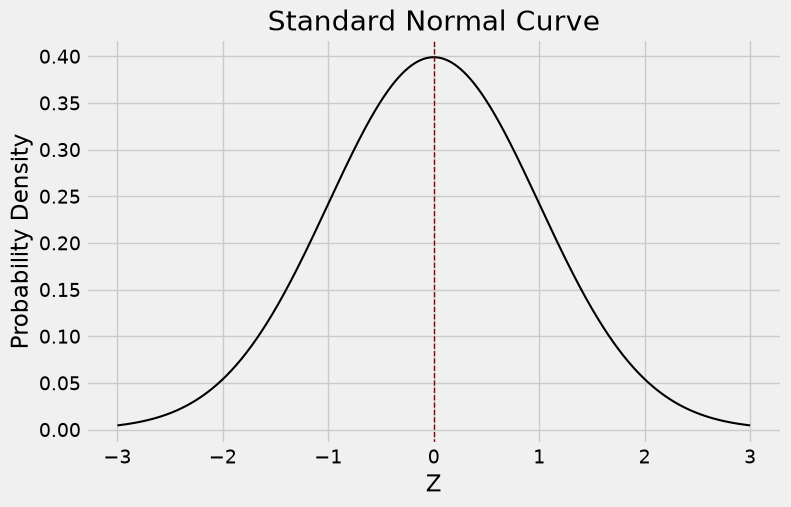

In [2]:

mu = 0
sigma = 1
x = 0

# Generate points along the curve
x_vals = np.linspace(mu - 3*sigma, mu + 3*sigma, 1000)
y_vals = sci.norm.pdf(x_vals, loc=mu, scale=sigma)

fig, ax = plots.subplots(figsize=(8, 5))
ax.plot(x_vals, y_vals, color='black', linewidth=1.5)

# Shade the area where X < 85 (i.e., P(X < 85))
#shade_x = np.linspace(mu - 4*sigma, x, 500)
#shade_y = sci.norm.pdf(shade_x, loc=mu, scale=sigma)
#ax.fill_between(shade_x, shade_y, color='steelblue', alpha=0.5)

# Add a vertical line at x and label the probability
p = sci.norm.cdf(x, loc=mu, scale=sigma)
ax.axvline(x, color='darkred', linestyle='--', linewidth=1)
ax.set_title(f"Standard Normal Curve")
#ax.set_title(f"P(X < {x}) = {p:.4f}")
ax.set_xlabel("Z")
ax.set_ylabel("Probability Density")

plots.show()

### Functions
Finding the probability at a particular z-score.  
Since the area directly under a single point of a curve is zero, we will find the area less than, greater than, or between two values. 

|You want|Function|
|--------|--------|
|P(Z ≤ z)| `sci.norm.cdf(z)`|
|P(Z ≥ z)|`sci.norm.sf(z)`|
|P(a ≤ Z ≤ b)|`sci.norm.cdf(b) - sci.norm.cdf(a)`

Create a function that will plot the curve shaded to represent area of the probability.

In [1]:
def plot_snormal_shaded(mu, sigma, lower=None, upper=None):
    """
    Plots a normal distribution curve with a shaded probability region.
    
    Parameters:
        mu, sigma : mean and standard deviation of the distribution
        lower, upper : bounds of the shaded region.
                       - lower=None -> shades from left tail up to `upper` (P(X < upper))
                       - upper=None -> shades from `lower` to right tail (P(X > lower))
                       - both given -> shades between them (P(lower < X < upper))
    """
    x_vals = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
    y_vals = sci.norm.pdf(x_vals, loc=mu, scale=sigma)

    fig, ax = plots.subplots(figsize=(8, 5))
    ax.plot(x_vals, y_vals, color='black', linewidth=1.5)

    # Determine shading range and compute probability
    if lower is None:
        x1 = x2 = upper
        shade_x = np.linspace(mu - 4*sigma, upper, 500)
        label = f"P(Z < {upper:.2f})"
    elif upper is None:
        x1 = x2 = lower
        shade_x = np.linspace(lower, mu + 4*sigma, 500)
        label = f"P(Z > {lower:.2f})"
    else:
        x1 = lower
        x2 = upper
        shade_x = np.linspace(lower, upper, 500)
        label = f"P({lower:.2f} < Z < {upper:.2f})"

    shade_y = sci.norm.pdf(shade_x, loc=mu, scale=sigma)
    ax.fill_between(shade_x, shade_y, color='steelblue', alpha=0.5)
    ax.axvline(x1, color='darkred', linestyle='--', linewidth=1)
    ax.axvline(x2, color='darkred', linestyle='--', linewidth=1)
    ax.set_title(label)
    ax.set_xlabel("Z")
    ax.set_ylabel("Probability Density")
    plots.show()


**EXAMPLES:**  
Find the probabilities and shade the curve for the following questions refering to a standard normal distribution.  
1. Find the probability z would be less than or equal to 0.5.

In [4]:
p1 = sci.norm.cdf(0.5)
print("P(Z < 0.5)=", p1)

P(Z < 0.5)= 0.6914624612740131


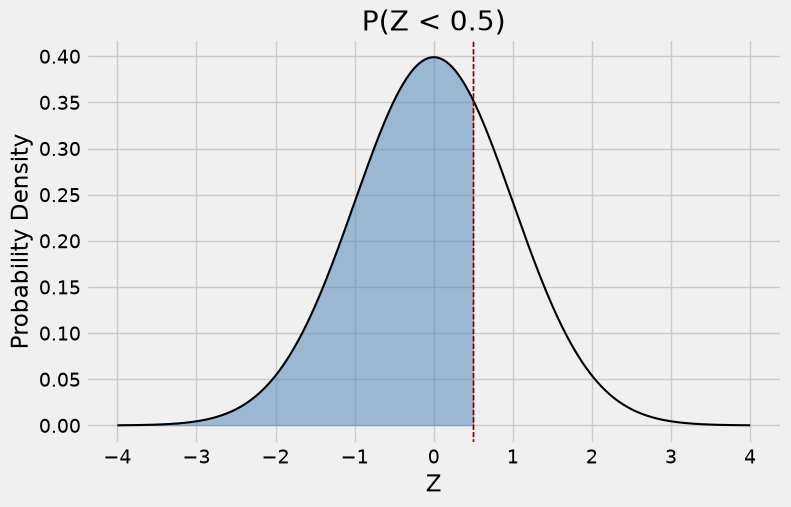

In [5]:
mu = 0
sigma = 1
z = 0.5 
plot_snormal_shaded(mu, sigma, upper=z)

2. Find the probability z would be greater than or equal to 1.2.

In [6]:
p2 = sci.norm.sf(1.2)
print("P(X > 1.2)=",p2)

P(X > 1.2)= 0.11506967022170822


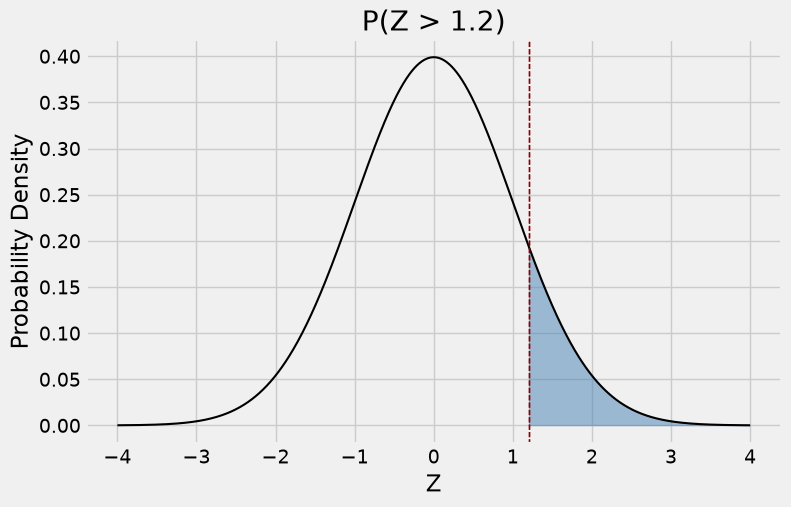

In [7]:
mu = 0
sigma = 1
z = 1.2 
plot_snormal_shaded(mu, sigma, lower=z)

3. Find the probability z would be between -2 and 1.3.

In [8]:
p3 = sci.norm.cdf(1.3) - sci.norm.cdf(-2)
print("P(-2 < X  < 1.3)=",p3)

P(-2 < X  < 1.3)= 0.8804493834662105


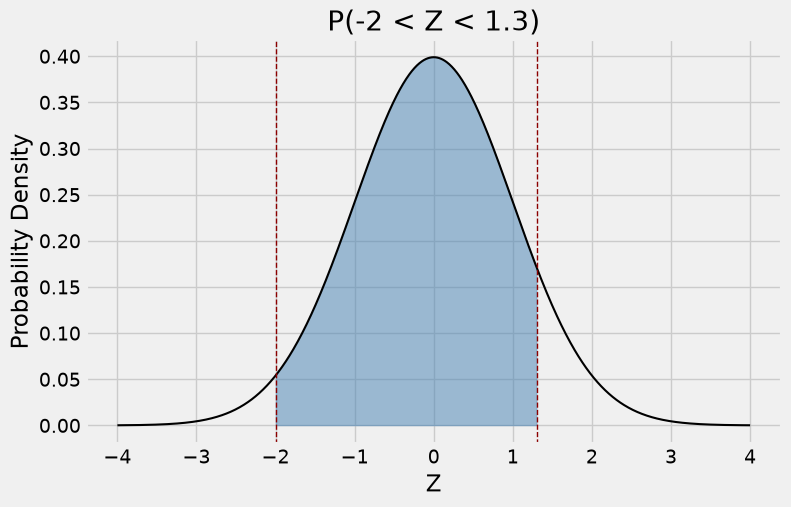

In [9]:
mu = 0
sigma = 1
z1 = -2
z2 = 1.3
plot_snormal_shaded(mu, sigma, lower=z1, upper=z2)

4. Find the probability z would be at most -1 or at least or  2. 

In [10]:
p_lower = sci.norm.cdf(-1)
p_upper = sci.norm.sf(2)
p4 = p_lower + p_upper
print("P(-1 < Z or  Z > 2)=",p4)

P(-1 < Z or  Z > 2)= 0.18140538587963628


In [11]:
def plot_snormal_two_tail(mu, sigma, lower, upper, title=None):
    """
    Plots P(Z < lower or Z > upper) -- shades both tails outside [lower, upper].
    """
    x_vals = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
    y_vals = sci.norm.pdf(x_vals, loc=mu, scale=sigma)

    fig, ax = plots.subplots(figsize=(8, 5))
    ax.plot(x_vals, y_vals, color='black', linewidth=1.5)

    # Lower tail: Z < lower
    lower_x = np.linspace(mu - 4*sigma, lower, 500)
    lower_y = sci.norm.pdf(lower_x, loc=mu, scale=sigma)
    ax.fill_between(lower_x, lower_y, color='steelblue', alpha=0.5)

    # Upper tail: Z > upper
    upper_x = np.linspace(upper, mu + 4*sigma, 500)
    upper_y = sci.norm.pdf(upper_x, loc=mu, scale=sigma)
    ax.fill_between(upper_x, upper_y, color='steelblue', alpha=0.5)

    label = f"P(X < {lower} or X > {upper})"
    ax.set_title(title or label)
    ax.set_xlabel("X")
    ax.set_ylabel("Probability Density")
    plots.show()


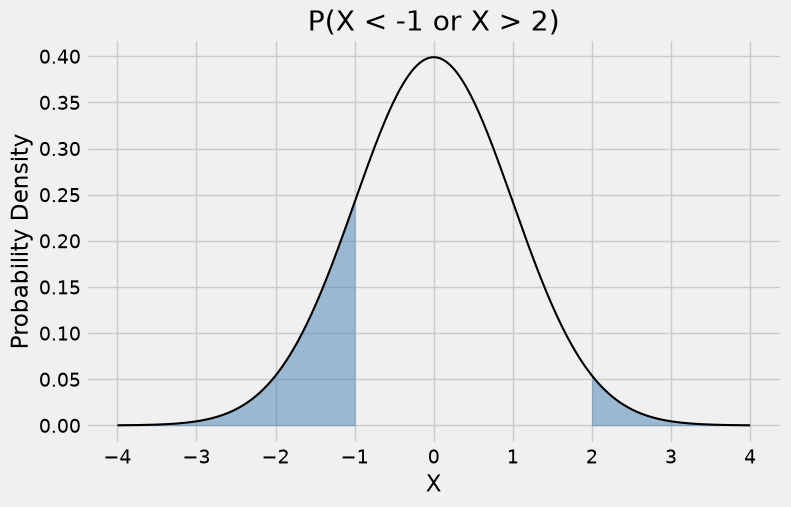

In [12]:
mu = 0
sigma = 1
lower = -1
upper = 2
plot_snormal_two_tail(mu, sigma, lower, upper)

### Functions
Finding the z-score given a particular probability or area. These are refered to as inverse problems.  
*Note: If a problem refers to "percentile" it is refering to the area to the left.*

|You want|Function|
|--------|--------|
|z for a given cumulative prob | sci.norm.ppf(p)
|z for a given upper-tail prob | sci.norm.isf(p)

**EXAMPLES:**  
Find z then draw the curve of the following standard normal curve probabilities or areas.

1. Find the z-score when the area to the left is 0.43

In [39]:
z1 = sci.norm.ppf(0.07)
print("Z = ", z1)

Z =  -1.4757910281791706


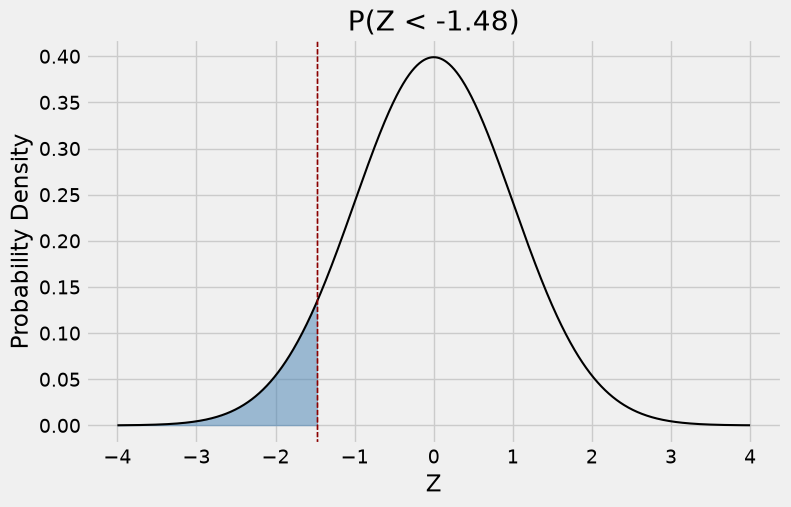

In [40]:
mu = 0
sigma = 1
z = z1
plot_snormal_shaded(mu, sigma, upper=z)

2. Find the z-score when the area to the right is 0.24

In [15]:
z2 = sci.norm.isf(0.24)
print("Z = ", z2)

Z =  0.7063025628400874


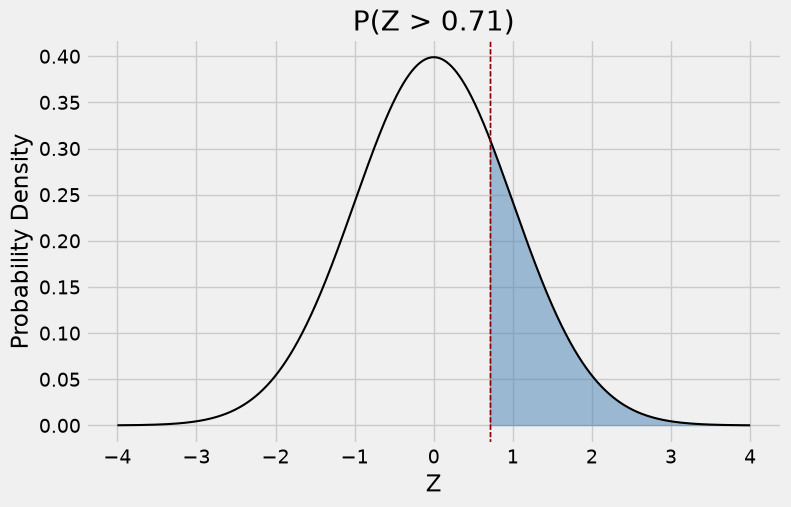

In [20]:
mu = 0
sigma = 1
z = z2
plot_snormal_shaded(mu, sigma, lower=z)

3. Find the z-score when the percentile is the 67th of standard normal.

In [21]:
z3 = sci.norm.ppf(0.67)
print("Z = ", z3)

Z =  0.4399131656732339


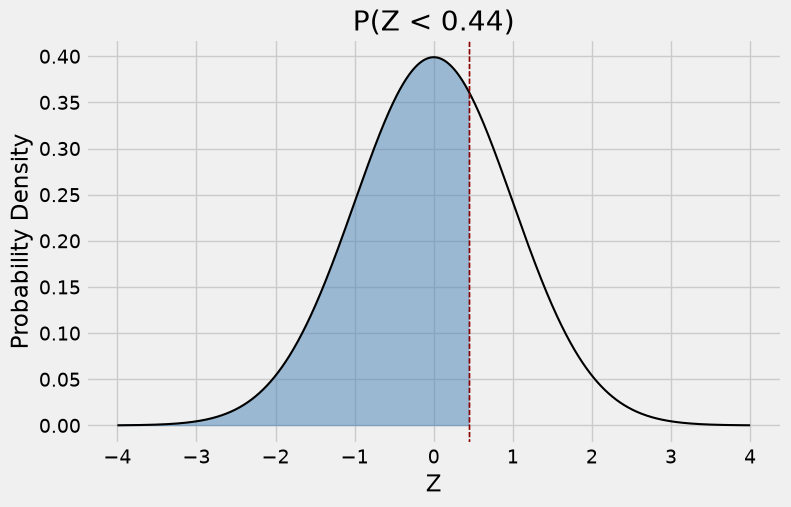

In [22]:
mu = 0
sigma = 1
z = z3
plot_snormal_shaded(mu, sigma, upper=z)

4. Find the z-score when $P(Z>c) = 0.15$

In [32]:
z4 = sci.norm.isf(0.15)
print("Z = ", z4)

Z =  1.0364333894937898


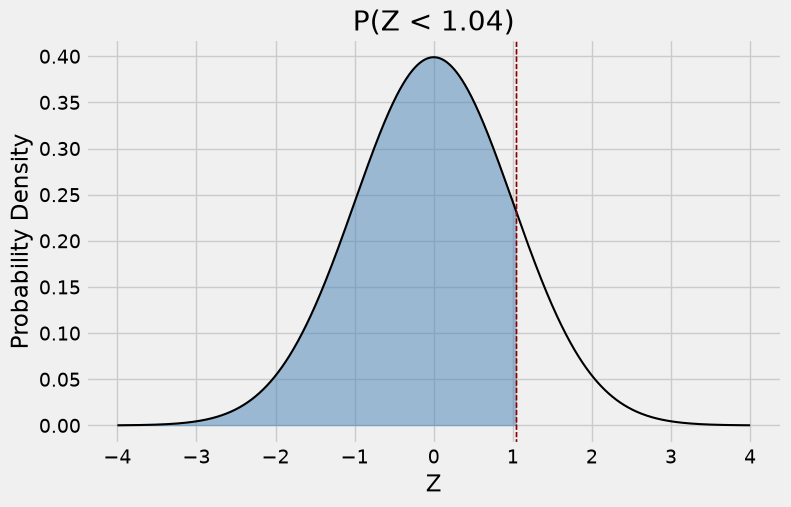

In [33]:
mu = 0
sigma = 1
z = z4
plot_snormal_shaded(mu, sigma, upper=z)

5. Find the z-score when $P(Z>c) = 0.31$

In [34]:
z5 = sci.norm.ppf(0.31)
print("Z = ", z5)

Z =  -0.4958503473474533


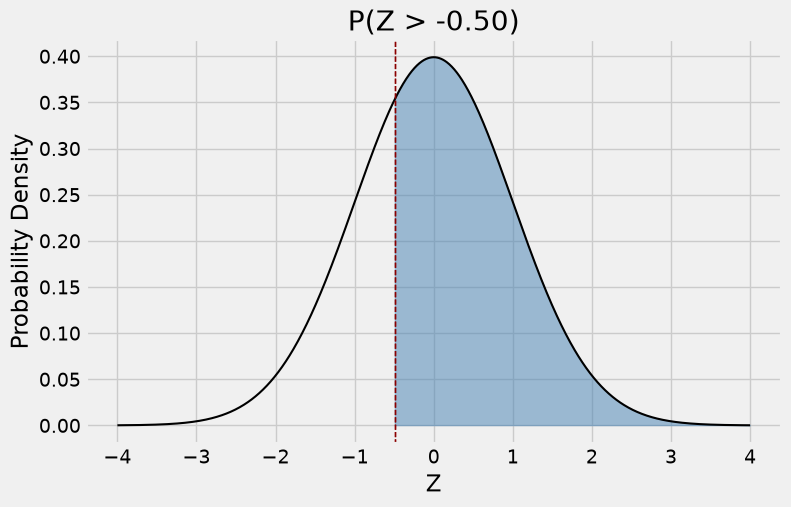

In [35]:
mu = 0
sigma = 1
z = z5
plot_snormal_shaded(mu, sigma, lower=z5)

***QUESTIONS:***
1. Find $P(0 < z < 1)$. Round to two decimal places, then convert to a percentage. Plot a picture of what you are finding. How close is it to the Empirical Rule estimate for that same area?
2. Find $P(z > -2)$. Round to three decimal places, then convert to a percentage. Plot a picture of what you are finding. How close is it to the Empirical Rule estimate for that same area?
3. Find the probability that a randomly selected z-score will be between -2.34 and 1.12.
4. Find the z-score corresponding to the top 0.12 of the area of the standard normal curve
5. The homework says to find c if P(z < c) = 0.7547.  
    a.	Is the 0.7547 on the number line or in the bell-shaped area? How do you know?  
    b.	Would c be on the number line or in the bell-shaped area? How do you know?  
    c.  Find c.
